# Étape 4 : le modèle à facteurs explique-t-il les rendements ?

On estime, pour une cible $i$, la régression multiple **contemporaine** (rendement du mois $t$ contre facteurs du mois $t$) :

$$R_{i,t} - R_{f,t} = \alpha_i + \beta_i\,\mathrm{MKT}_t + s_i\,\mathrm{SMB}_t + h_i\,\mathrm{HML}_t + r_i\,\mathrm{RMW}_t + c_i\,\mathrm{CMA}_t + m_i\,\mathrm{MOM}_t + \varepsilon_{i,t}$$

Le but est **explicatif** : mesurer quelle part des variations de rendement les facteurs expliquent, sans chercher à prévoir le mois suivant.

Deux cibles :
1. une action seule : **Apple (AAPL)** ;
2. un **portefeuille diversifié** de grandes capitalisations américaines, équipondéré et rééquilibré chaque mois.

On ajoute deux ETF en point de comparaison : SPY (S&P 500 pondéré par la capitalisation) et RSP (S&P 500 équipondéré).

In [1]:
import io
import zipfile
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson, jarque_bera

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.precision", 3)
pd.set_option("display.width", 130)
rng = np.random.default_rng(2026)

## 1. Données

- **Facteurs** : mêmes fichiers qu'à l'étape 3 (Kenneth French, base CRSP d'août 2026).
- **Cours** : clôtures mensuelles ajustées des dividendes et des divisions d'actions (Yahoo Finance), téléchargées avec [`scripts/telecharger_cours.py`](../scripts/telecharger_cours.py).

Le rendement mensuel d'un titre est $R_{t} = P_t / P_{t-1} - 1$, exprimé en % pour être dans la même unité que les facteurs. Comme le cours est ajusté, ce rendement inclut les dividendes.

In [2]:
def lire_bloc_mensuel(chemin_zip):
    # Lit le premier bloc de données (mensuel) d'un CSV de Kenneth French.
    with zipfile.ZipFile(chemin_zip) as z:
        texte = z.read(z.namelist()[0]).decode("latin-1")
    lignes = texte.splitlines()
    debut = next(i for i, l in enumerate(lignes) if l.startswith(","))
    bloc = [lignes[debut]]
    for l in lignes[debut + 1:]:
        if not l.strip() or not l.strip()[0].isdigit():
            break
        bloc.append(l)
    df = pd.read_csv(io.StringIO("\n".join(bloc)), index_col=0)
    df.columns = df.columns.str.strip()
    df.index = pd.PeriodIndex(df.index.astype(str), freq="M")
    return df.astype(float)


facteurs = lire_bloc_mensuel(RAW / "F-F_Research_Data_5_Factors_2x3_CSV.zip").join(
    lire_bloc_mensuel(RAW / "F-F_Momentum_Factor_CSV.zip"), how="inner")
FACTEURS = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom"]

cours = pd.read_csv(RAW / "cours_mensuels.csv", index_col=0)
cours.index = pd.PeriodIndex(cours.index.astype(str).str[:7], freq="M")
cours = cours.sort_index()
cours = cours[~cours.index.duplicated(keep="last")]
rendements = 100 * cours.pct_change(fill_method=None)

# composition du portefeuille, définie avec le script de téléchargement
sys.path.insert(0, str(ROOT / "scripts"))
from univers import PORTEFEUILLE

print(f"Facteurs : {facteurs.index.min()} -> {facteurs.index.max()}")
print(f"Cours : {cours.shape[1]} séries, {cours.index.min()} -> {cours.index.max()}")

Facteurs : 1963-07 -> 2026-08
Cours : 113 séries, 1990-01 -> 2026-08


## 2. Construction du portefeuille diversifié

**Composition** : 110 grandes capitalisations américaines réparties sur les 11 secteurs GICS, retenues si elles ont un cours chaque mois sur toute la période d'étude.

**Pondération** : chaque action pèse $1/N$, et on rééquilibre chaque mois :

$$R_{P,t} = \frac{1}{N} \sum_{j=1}^{N} R_{j,t}$$

**Pourquoi ce choix :**
- *Équipondéré plutôt que pondéré par la capitalisation* : le facteur marché (Mkt-RF) est déjà un portefeuille pondéré par la capitalisation. Un portefeuille construit de la même manière l'expliquerait presque par définition. L'équipondération donne un portefeuille différent du marché, qui reste un vrai test du modèle.
- *Plusieurs secteurs* : le risque propre à un secteur (pétrole, banques...) se compense entre secteurs.
- *Plus de 100 titres* : avec $N$ titres de même volatilité spécifique $\sigma_\varepsilon$ et des chocs spécifiques indépendants, la variance spécifique du portefeuille équipondéré vaut $\sigma_\varepsilon^2 / N$. Elle disparaît quand $N$ grandit, alors que le risque commun aux facteurs reste.

**Limite, le biais du survivant** : les titres sont des entreprises toujours cotées aujourd'hui. Celles qui ont fait faillite ou ont été rachetées depuis 2000 sont absentes, ce qui gonfle le rendement moyen du portefeuille et donc son alpha. L'effet sur le $R^2$, qui mesure la part de variance expliquée, est bien plus faible.

In [3]:
DEBUT, FIN = pd.Period("2000-01", "M"), min(facteurs.index.max(), rendements.index.max())
periode = pd.period_range(DEBUT, FIN, freq="M")

candidats = [t for liste in PORTEFEUILLE.values() for t in liste]
disponibles = [t for t in candidats if t in rendements.columns
               and rendements.loc[periode, t].notna().all()]
exclus = sorted(set(candidats) - set(disponibles))
secteur_de = {t: s for s, liste in PORTEFEUILLE.items() for t in liste}

print(f"Période d'étude : {DEBUT} -> {FIN} ({len(periode)} mois)")
print(f"Titres retenus : {len(disponibles)} / {len(candidats)}")
print("Titres exclus (historique incomplet) :", exclus or "aucun")
pd.Series([secteur_de[t] for t in disponibles]).value_counts().rename("nombre de titres").to_frame()

Période d'étude : 2000-01 -> 2026-08 (320 mois)
Titres retenus : 107 / 110
Titres exclus (historique incomplet) : ['AEP', 'BK', 'MMC']


,nombre de titres
Industrie,17
Santé,15
Technologie,14
Finance,13
Consommation de base,12
Consommation discrétionnaire,10
Énergie,8
Services aux collectivités,6
Matériaux,6
Communication,4


In [4]:
R = rendements.loc[periode]
F = facteurs.loc[periode]

cibles = pd.DataFrame({
    "Apple (AAPL)": R["AAPL"],
    "Portefeuille diversifié": R[disponibles].mean(axis=1),
    "SPY (S&P 500)": R["SPY"],
    "RSP (S&P 500 équipondéré)": R["RSP"],
})
exces = cibles.sub(F["RF"], axis=0)

# RSP n'existe que depuis mai 2003 : on le garde sur sa propre période
print(exces.notna().sum().rename("mois disponibles"))
desc = pd.DataFrame({
    "rendement annualisé (%)": 12 * cibles.mean(),
    "volatilité annualisée (%)": np.sqrt(12) * cibles.std(),
})
desc

Apple (AAPL)                 320
Portefeuille diversifié      320
SPY (S&P 500)                320
RSP (S&P 500 équipondéré)    279
Name: mois disponibles, dtype: int64


,rendement annualisé (%),volatilité annualisée (%)
Apple (AAPL),30.235,37.468
Portefeuille diversifié,13.325,14.755
SPY (S&P 500),9.132,15.151
RSP (S&P 500 équipondéré),11.791,16.403


## 3. Estimation

Moindres carrés ordinaires (MCO). Les t-stats utilisent les **erreurs standard de Newey-West** (6 retards), robustes à l'hétéroscédasticité et à l'autocorrélation des résidus. C'est plus prudent que les erreurs standard classiques, qui supposent des résidus indépendants et de variance constante.

Mesures retenues :
- $R^2 = 1 - \dfrac{\sum_t \hat\varepsilon_t^2}{\sum_t (y_t - \bar y)^2}$ : part de la variance du rendement expliquée par les facteurs.
- $R^2$ ajusté $= 1 - (1 - R^2)\dfrac{T-1}{T-k-1}$, avec $k = 6$ facteurs : pénalise le nombre de variables.
- Alpha annualisé $= 12\,\hat\alpha$ : rendement moyen non expliqué par les facteurs.
- Volatilité spécifique annualisée $= \sqrt{12}\,\hat\sigma_\varepsilon$ : le risque propre à la cible.
- $R^2$ du CAPM (marché seul) : pour mesurer ce qu'apportent les cinq autres facteurs.

In [5]:
def regression(y, X, retards=6):
    donnees = pd.concat([y, X], axis=1).dropna()
    modele = sm.OLS(donnees.iloc[:, 0], sm.add_constant(donnees.iloc[:, 1:]))
    return modele.fit(cov_type="HAC", cov_kwds={"maxlags": retards})


resultats = {nom: regression(exces[nom], F[FACTEURS]) for nom in exces.columns}
capm = {nom: regression(exces[nom], F[["Mkt-RF"]]) for nom in exces.columns}

synthese = pd.DataFrame({
    nom: {
        "mois": int(res.nobs),
        "R²": res.rsquared,
        "R² ajusté": res.rsquared_adj,
        "R² du CAPM": capm[nom].rsquared,
        "alpha annualisé (%)": 12 * res.params["const"],
        "t-stat alpha": res.tvalues["const"],
        "volatilité totale (%)": np.sqrt(12) * res.model.endog.std(ddof=1),
        "volatilité spécifique (%)": np.sqrt(12) * np.sqrt(res.mse_resid),
    } for nom, res in resultats.items()
})
synthese

,Apple (AAPL),Portefeuille diversifié,SPY (S&P 500),RSP (S&P 500 équipondéré)
mois,320.000,320.000,320.000,279.000
R²,0.370,0.939,0.994,0.965
R² ajusté,0.358,0.938,0.994,0.964
R² du CAPM,0.300,0.835,0.979,0.921
alpha annualisé (%),20.889,2.887,-0.225,-0.637
t-stat alpha,3.446,4.118,-0.991,-0.869
volatilité totale (%),37.500,14.778,15.183,16.434
volatilité spécifique (%),30.055,3.692,1.217,3.122


In [6]:
def tableau_coefficients(res):
    return pd.DataFrame({
        "coefficient": res.params,
        "erreur standard (NW)": res.bse,
        "t-stat": res.tvalues,
        "p-valeur": res.pvalues,
    }).rename(index={"const": "alpha (mensuel, %)"})


for nom in ["Apple (AAPL)", "Portefeuille diversifié"]:
    print(f"\n=== {nom} ===")
    display(tableau_coefficients(resultats[nom]).round(3))


=== Apple (AAPL) ===


,coefficient,erreur standard (NW),t-stat,p-valeur
"alpha (mensuel, %)",1.741,0.505,3.446,0.001
Mkt-RF,1.214,0.153,7.911,0.000
SMB,0.245,0.174,1.409,0.159
HML,-0.567,0.178,-3.180,0.001
RMW,0.252,0.143,1.761,0.078
CMA,-0.674,0.309,-2.183,0.029
Mom,-0.027,0.150,-0.181,0.856



=== Portefeuille diversifié ===


,coefficient,erreur standard (NW),t-stat,p-valeur
"alpha (mensuel, %)",0.241,0.058,4.118,0.000
Mkt-RF,0.910,0.016,57.722,0.000
SMB,-0.015,0.026,-0.590,0.555
HML,0.194,0.031,6.231,0.000
RMW,0.151,0.025,6.015,0.000
CMA,0.253,0.040,6.334,0.000
Mom,-0.064,0.016,-4.081,0.000


In [7]:
print(resultats["Portefeuille diversifié"].summary())

                               OLS Regression Results                              
Dep. Variable:     Portefeuille diversifié   R-squared:                       0.939
Model:                                 OLS   Adj. R-squared:                  0.938
Method:                      Least Squares   F-statistic:                     1032.
Date:                     Fri, 16 Oct 2026   Prob (F-statistic):          6.82e-203
Time:                             15:34:51   Log-Likelihood:                -470.91
No. Observations:                      320   AIC:                             955.8
Df Residuals:                          313   BIC:                             982.2
Df Model:                                6                                         
Covariance Type:                       HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
co

## 4. Graphiques

In [8]:
SURFACE, TEXTE, TEXTE2, GRILLE = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLEU, ORANGE, AQUA, JAUNE, MAGENTA, VERT = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"
COULEURS = {"Mkt-RF": BLEU, "SMB": ORANGE, "HML": AQUA, "RMW": JAUNE, "CMA": MAGENTA, "Mom": VERT}
GRIS_SPECIFIQUE = "#b9b8b2"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10,
    "text.color": TEXTE, "axes.labelcolor": TEXTE2, "xtick.color": TEXTE2, "ytick.color": TEXTE2,
    "axes.edgecolor": GRILLE, "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})


def sauver(fig, nom):
    fig.savefig(FIG / nom, dpi=200, bbox_inches="tight")

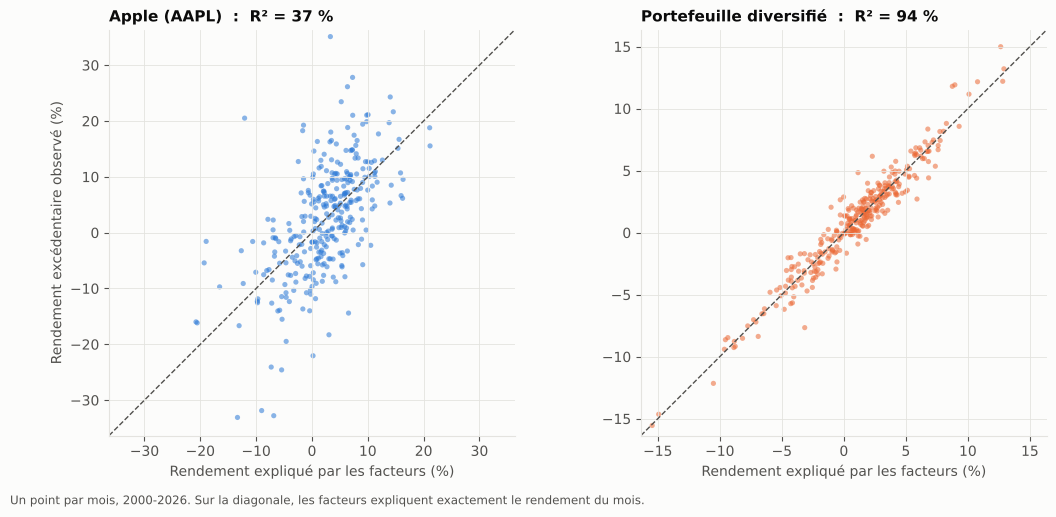

In [9]:
# Rendement observé contre rendement expliqué par les facteurs
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, nom, col in zip(axes, ["Apple (AAPL)", "Portefeuille diversifié"], [BLEU, ORANGE]):
    res = resultats[nom]
    y = res.model.endog
    ajuste = res.fittedvalues
    ax.scatter(ajuste, y, s=14, color=col, alpha=0.55, edgecolor="none")
    lim = np.nanpercentile(np.abs(np.r_[y, ajuste]), 99.5) * 1.1
    ax.plot([-lim, lim], [-lim, lim], color=TEXTE2, lw=1, ls="--")
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.set_xlabel("Rendement expliqué par les facteurs (%)")
    ax.set_title(f"{nom}  :  R² = {res.rsquared:.0%}".replace("%", " %"))
axes[0].set_ylabel("Rendement excédentaire observé (%)")
fig.text(0.01, -0.02, "Un point par mois, 2000-2026. Sur la diagonale, les facteurs expliquent exactement le rendement du mois.",
         fontsize=8.5, color=TEXTE2)
fig.tight_layout()
sauver(fig, "regression_observe_vs_explique.png")
plt.show()

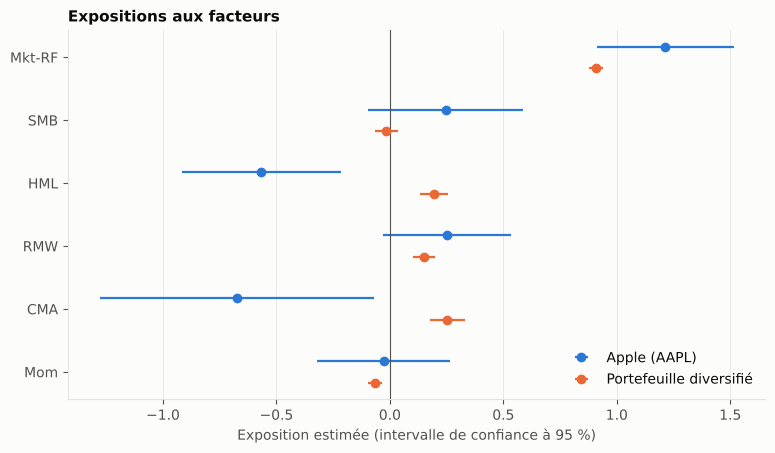

In [10]:
# Expositions estimées avec intervalle de confiance à 95 % (Newey-West)
fig, ax = plt.subplots(figsize=(9, 4.8))
y_pos = np.arange(len(FACTEURS))
decalage = {"Apple (AAPL)": -0.17, "Portefeuille diversifié": 0.17}
for nom, col in zip(decalage, [BLEU, ORANGE]):
    res = resultats[nom]
    coef = res.params[FACTEURS]
    ic = res.conf_int().loc[FACTEURS]
    ax.errorbar(coef, y_pos + decalage[nom], xerr=[coef - ic[0], ic[1] - coef], fmt="o",
                color=col, ms=6, lw=1.6, capsize=0, label=nom)
ax.axvline(0, color=TEXTE2, lw=0.8)
ax.set_yticks(y_pos, FACTEURS)
ax.invert_yaxis()
ax.set_xlabel("Exposition estimée (intervalle de confiance à 95 %)")
ax.set_title("Expositions aux facteurs")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
sauver(fig, "regression_expositions.png")
plt.show()

### Décomposition de la variance

Avec $y_t = \alpha + \sum_k b_k F_{k,t} + \varepsilon_t$ estimé par MCO, la variance se décompose exactement :

$$\mathrm{Var}(y) = \sum_k b_k\,\mathrm{Cov}(F_k, y) + \mathrm{Var}(\varepsilon)$$

En divisant par $\mathrm{Var}(y)$, la contribution du facteur $k$ vaut $b_k\,\mathrm{Cov}(F_k, y)/\mathrm{Var}(y)$. La somme des contributions des facteurs est égale au $R^2$, et le reste ($1 - R^2$) est la part spécifique. Une contribution peut être légèrement négative quand deux facteurs corrélés se compensent.

In [11]:
def decomposition(res):
    y = pd.Series(res.model.endog)
    X = pd.DataFrame(res.model.exog, columns=res.model.exog_names)[FACTEURS]
    contrib = {k: res.params[k] * np.cov(X[k], y, ddof=1)[0, 1] / y.var(ddof=1) for k in FACTEURS}
    contrib["Spécifique"] = 1 - sum(contrib.values())
    return pd.Series(contrib)


decomp = pd.DataFrame({nom: decomposition(res) for nom, res in resultats.items()}).T
assert np.allclose(decomp[FACTEURS].sum(axis=1), [r.rsquared for r in resultats.values()])
(100 * decomp).round(1)

,Mkt-RF,SMB,HML,RMW,CMA,Mom,Spécifique
Apple (AAPL),27.8,1.0,4.6,-1.6,4.9,0.2,63.0
Portefeuille diversifié,88.3,-0.2,3.8,-1.5,0.3,3.2,6.1
SPY (S&P 500),100.9,-1.5,-0.0,-0.9,-0.3,1.2,0.6
RSP (S&P 500 équipondéré),87.2,3.9,2.1,-0.7,0.0,3.9,3.5


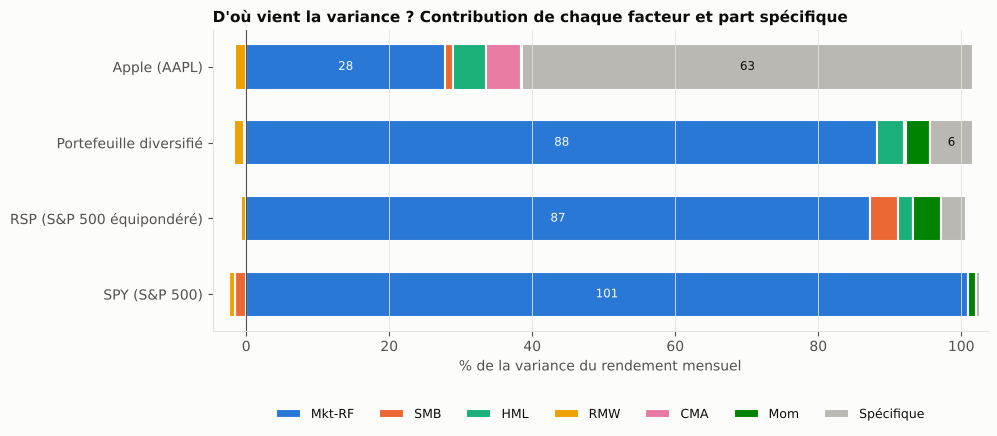

In [12]:
ordre = ["Apple (AAPL)", "Portefeuille diversifié", "RSP (S&P 500 équipondéré)", "SPY (S&P 500)"]
fig, ax = plt.subplots(figsize=(10, 3.9))
for i, nom in enumerate(ordre):
    gauche_pos, gauche_neg = 0.0, 0.0
    for k in FACTEURS + ["Spécifique"]:
        v = 100 * decomp.loc[nom, k]
        col = GRIS_SPECIFIQUE if k == "Spécifique" else COULEURS[k]
        if v >= 0:
            ax.barh(i, v, left=gauche_pos, color=col, height=0.6, edgecolor=SURFACE, linewidth=1.5,
                    label=k if i == 0 else None)
            if v > 6:
                ax.text(gauche_pos + v / 2, i, f"{v:.0f}", ha="center", va="center", fontsize=8.5,
                        color="white" if k in ("Mkt-RF", "Mom") else TEXTE)
            gauche_pos += v
        else:
            ax.barh(i, v, left=gauche_neg, color=col, height=0.6, edgecolor=SURFACE, linewidth=1.5,
                    label=k if i == 0 else None)
            gauche_neg += v
ax.set_yticks(range(len(ordre)), ordre)
ax.invert_yaxis()
ax.axvline(0, color=TEXTE2, lw=0.8)
ax.set_xlim(min(-3, 100 * decomp.clip(upper=0).sum(axis=1).min() - 2),
            max(100, 100 * decomp.clip(lower=0).sum(axis=1).max()) + 1)
ax.set_xlabel("% de la variance du rendement mensuel")
ax.set_title("D'où vient la variance ? Contribution de chaque facteur et part spécifique")
ax.legend(ncol=7, loc="upper center", bbox_to_anchor=(0.5, -0.22), fontsize=9)
ax.grid(axis="y", visible=False)
sauver(fig, "regression_decomposition_variance.png")
plt.show()

### Le R² en fonction du nombre d'actions

Pour voir la diversification à l'œuvre, on tire au hasard $N$ titres parmi ceux du portefeuille ($N$ = 1, 2, 5, 10, 20, 30, 50, 75, 100), on forme le portefeuille équipondéré et on mesure le $R^2$ de la régression. On répète 300 fois pour chaque $N$.

In [13]:
TAILLES = [1, 2, 5, 10, 20, 30, 50, 75, 100]
TIRAGES = 300
Xc = sm.add_constant(F[FACTEURS]).values
Rex = R[disponibles].sub(F["RF"], axis=0).values


def r2_rapide(y):
    beta, *_ = np.linalg.lstsq(Xc, y, rcond=None)
    resid = y - Xc @ beta
    return 1 - resid.var() / y.var()


simu = {}
for n in TAILLES:
    if n > len(disponibles):
        continue
    simu[n] = [r2_rapide(Rex[:, rng.choice(len(disponibles), n, replace=False)].mean(axis=1))
               for _ in range(TIRAGES)]
simu = pd.DataFrame(simu)
r2_par_taille = simu.quantile([0.1, 0.5, 0.9]).T
r2_par_taille.columns = ["10e centile", "médiane", "90e centile"]
(100 * r2_par_taille).round(1)

,10e centile,médiane,90e centile
1,18.1,37.0,54.4
2,30.3,47.2,62.3
5,54.1,66.4,74.3
10,70.2,78.3,82.8
20,82.1,85.6,88.7
30,86.1,89.0,91.1
50,90.2,91.7,92.8
75,92.2,93.0,93.7
100,93.4,93.7,94.0


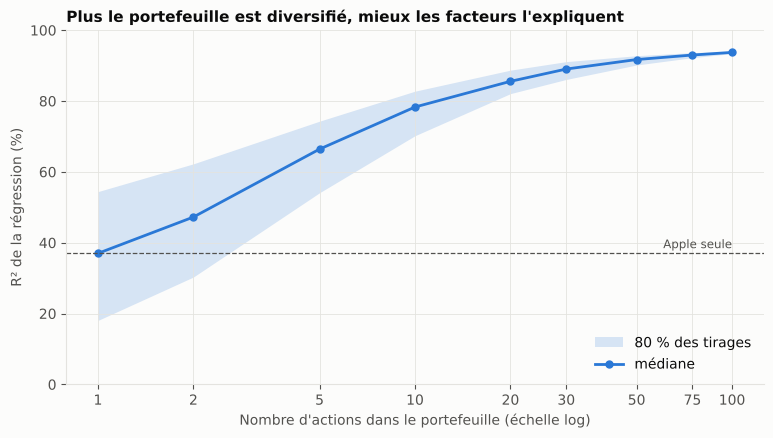

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.6))
n = r2_par_taille.index.values
ax.fill_between(n, 100 * r2_par_taille["10e centile"], 100 * r2_par_taille["90e centile"],
                color=BLEU, alpha=0.18, lw=0, label="80 % des tirages")
ax.plot(n, 100 * r2_par_taille["médiane"], color=BLEU, lw=2, marker="o", ms=5, label="médiane")
ax.axhline(100 * resultats["Apple (AAPL)"].rsquared, color=TEXTE2, lw=0.9, ls="--")
ax.text(n[-1], 100 * resultats["Apple (AAPL)"].rsquared + 1.5, "Apple seule", color=TEXTE2,
        fontsize=8.5, ha="right")
ax.set_xscale("log")
ax.set_xticks(n, [str(v) for v in n])
ax.minorticks_off()
ax.set_ylim(0, 100)
ax.set_xlabel("Nombre d'actions dans le portefeuille (échelle log)")
ax.set_ylabel("R² de la régression (%)")
ax.set_title("Plus le portefeuille est diversifié, mieux les facteurs l'expliquent")
ax.legend(loc="lower right")
sauver(fig, "regression_r2_nombre_actions.png")
plt.show()

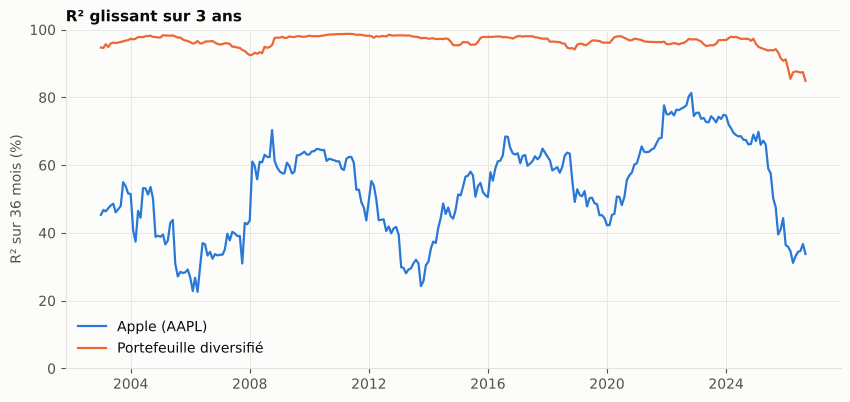

In [15]:
# Stabilité dans le temps : R² sur 36 mois glissants
def r2_glissant(y, X, fenetre=36):
    donnees = pd.concat([y, X], axis=1).dropna()
    valeurs = {}
    for fin in range(fenetre, len(donnees) + 1):
        bloc = donnees.iloc[fin - fenetre:fin]
        valeurs[bloc.index[-1]] = sm.OLS(bloc.iloc[:, 0], sm.add_constant(bloc.iloc[:, 1:])).fit().rsquared
    return pd.Series(valeurs)


fig, ax = plt.subplots(figsize=(10, 4.4))
for nom, col in [("Apple (AAPL)", BLEU), ("Portefeuille diversifié", ORANGE)]:
    s = r2_glissant(exces[nom], F[FACTEURS])
    ax.plot(s.index.to_timestamp(how="end"), 100 * s, color=col, lw=1.6, label=nom)
ax.set_ylim(0, 100)
ax.set_ylabel("R² sur 36 mois (%)")
ax.set_title("R² glissant sur 3 ans")
ax.legend(loc="lower left")
sauver(fig, "regression_r2_glissant.png")
plt.show()

## 5. Diagnostic des résidus

- **Durbin-Watson** : proche de 2 si les résidus ne sont pas autocorrélés.
- **Jarque-Bera** : teste la normalité des résidus.
- **Breusch-Pagan** : teste si la variance des résidus dépend des facteurs (hétéroscédasticité).

Ces tests ne remettent pas en cause les coefficients estimés. Ils justifient l'usage des erreurs standard de Newey-West.

In [16]:
diag = {}
for nom, res in resultats.items():
    jb_stat, jb_p, asym, kurt = jarque_bera(res.resid)
    bp_p = het_breuschpagan(res.resid, res.model.exog)[1]
    diag[nom] = {"Durbin-Watson": durbin_watson(res.resid), "asymétrie": asym, "kurtosis": kurt,
                 "p-valeur Jarque-Bera": jb_p, "p-valeur Breusch-Pagan": bp_p}
pd.DataFrame(diag).round(3)

,Apple (AAPL),Portefeuille diversifié,SPY (S&P 500),RSP (S&P 500 équipondéré)
Durbin-Watson,1.970,1.914,2.268,1.845
asymétrie,-0.139,0.199,-0.070,-0.244
kurtosis,6.731,4.837,7.698,4.773
p-valeur Jarque-Bera,0.000,0.000,0.000,0.000
p-valeur Breusch-Pagan,0.010,0.715,0.005,0.268


In [17]:
# Apple sur tout son historique disponible, pour vérifier que le résultat ne dépend pas de la période
periode_longue = pd.period_range(max(pd.Period("1990-02", "M"), rendements["AAPL"].first_valid_index()), FIN, freq="M")
y_long = rendements.loc[periode_longue, "AAPL"] - facteurs.loc[periode_longue, "RF"]
res_long = regression(y_long, facteurs.loc[periode_longue, FACTEURS])
print(f"Apple {periode_longue[0]} -> {periode_longue[-1]} ({int(res_long.nobs)} mois) : "
      f"R² = {res_long.rsquared:.3f}, R² ajusté = {res_long.rsquared_adj:.3f}")
tableau_coefficients(res_long).round(3)

Apple 1990-02 -> 2026-08 (439 mois) : R² = 0.285, R² ajusté = 0.275


,coefficient,erreur standard (NW),t-stat,p-valeur
"alpha (mensuel, %)",1.517,0.495,3.063,0.002
Mkt-RF,1.044,0.141,7.401,0.000
SMB,0.343,0.161,2.126,0.034
HML,-0.620,0.205,-3.022,0.003
RMW,0.237,0.173,1.364,0.173
CMA,-0.689,0.312,-2.208,0.027
Mom,-0.151,0.126,-1.192,0.233
